# MVT-SPAR — Crash-Resistant GTSRB / VGG16 Experiment

This revised Colab notebook is designed to reduce RAM and GPU-memory pressure:
- It **does not load the complete GTSRB dataset into RAM**.
- Images are decoded and resized in batches using `tf.data`.
- Attack outputs are written incrementally to disk-backed `.npy` memmaps.
- Attack and defense stages save checkpoints after each condition.
- MVT-SPAR uses a batched TensorFlow Jacobi solver rather than launching thousands of separate CPU solvers.
- Full 4,000-image restoration is configurable; start with a small pilot before scaling up.

**Dataset labels:** supports standard GTSRB numeric class folders (`00000`–`00042`) and common per-class `GT-xxxxx.csv` files. It also prints a directory sample if automatic detection fails.

**Important:** if the ZIP contains only `Final_Training`, the 4,000 test images are a stratified holdout from that archive, not the official GTSRB test set.

## 1. Install packages

In [1]:
!pip -q install opencv-python-headless scikit-image pandas scikit-learn matplotlib reportlab tqdm

## 2. Imports and GPU memory configuration

In [2]:
import os, re, glob, json, time, random, zipfile, shutil, gc, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
warnings.filterwarnings('ignore')

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPUs:", gpus)
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Memory growth setting skipped:", e)

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Reproducibility and memory-safe configuration

In [3]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = 224
NUM_CLASSES = 43
TEST_SIZE = 4000
TRAIN_BATCH = 16
EVAL_BATCH = 8
EPOCHS_HEAD = 5
EPOCHS_FINE = 15

EPSILONS = [0.01, 0.03, 0.05, 0.1]
PATCH_SIZES = [2, 4, 6, 8]
ATTACK_STEPS = 40
MVT_K = 5                    # Increase to 10 after pilot validation
PDE_JACOBI_STEPS = 40        # Increase after checking convergence
PDE_EPSILON = 1.0
PDE_LAMBDA = 1.0
MVT_ALPHA = 2.0
EDGE_BETA = 10.0

# Start small to validate the full pipeline without crashing.
# Set to 4000 only after pilot run succeeds.
DEFENSE_LIMIT = 64
ATTACK_SAVE_DTYPE = np.float16  # saves disk space; cast back to float32 for inference

print("Configuration ready. Defense pilot size:", DEFENSE_LIMIT)

Configuration ready. Defense pilot size: 64


## 4. Mount Drive and locate ZIP

In [4]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_CANDIDATES = glob.glob('/content/drive/MyDrive/**/GTSRB.zip', recursive=True)
if not ZIP_CANDIDATES:
    raise FileNotFoundError(
        "GTSRB.zip not found in MyDrive. Upload it to Google Drive and rerun this cell."
    )
ZIP_PATH = ZIP_CANDIDATES[0]
print("Using ZIP:", ZIP_PATH)

ROOT_OUT = '/content/drive/MyDrive/GTSRB-MVT-SPAR'
SUBDIRS = ['Dataset_Split','Trained_Models','Adversarial_Images',
           'Restored_Images','Results_CSV','Figures','PDF_Report','Logs','Checkpoints']
for d in SUBDIRS:
    os.makedirs(os.path.join(ROOT_OUT,d), exist_ok=True)
print("Output folder:", ROOT_OUT)

Mounted at /content/drive
Using ZIP: /content/drive/MyDrive/personal /GTSRB.zip
Output folder: /content/drive/MyDrive/GTSRB-MVT-SPAR


## 5. Extract ZIP safely

In [5]:
EXTRACT_DIR = '/content/GTSRB_extracted'
os.makedirs(EXTRACT_DIR, exist_ok=True)

marker = os.path.join(EXTRACT_DIR, '.extracted_ok')
if not os.path.exists(marker):
    print("Extracting archive...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(EXTRACT_DIR)
    Path(marker).write_text("ok")
else:
    print("Extraction already present; skipping.")

print("Top-level entries:", os.listdir(EXTRACT_DIR)[:30])

Extracting archive...
Top-level entries: ['meta', 'train', 'Meta', 'Train', 'Test', 'Meta.csv', 'test', 'Train.csv', '.extracted_ok', 'Test.csv']


## 6. Inspect archive structure

In [6]:
for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = root.replace(EXTRACT_DIR, '').count(os.sep)
    if depth <= 3:
        print("  "*depth + os.path.basename(root) + f"  [dirs={len(dirs)}, files={len(files)}]")
    if depth >= 3:
        dirs[:] = []

GTSRB_extracted  [dirs=6, files=4]
  meta  [dirs=0, files=45]
  train  [dirs=43, files=0]
    17  [dirs=0, files=1110]
    14  [dirs=0, files=780]
    42  [dirs=0, files=240]
    30  [dirs=0, files=450]
    24  [dirs=0, files=270]
    12  [dirs=0, files=2100]
    38  [dirs=0, files=2070]
    27  [dirs=0, files=240]
    9  [dirs=0, files=1470]
    2  [dirs=0, files=2250]
    13  [dirs=0, files=2160]
    22  [dirs=0, files=390]
    20  [dirs=0, files=360]
    40  [dirs=0, files=360]
    11  [dirs=0, files=1320]
    19  [dirs=0, files=210]
    33  [dirs=0, files=689]
    0  [dirs=0, files=210]
    16  [dirs=0, files=420]
    37  [dirs=0, files=210]
    3  [dirs=0, files=1410]
    15  [dirs=0, files=630]
    41  [dirs=0, files=240]
    28  [dirs=0, files=540]
    23  [dirs=0, files=510]
    8  [dirs=0, files=1410]
    7  [dirs=0, files=1440]
    29  [dirs=0, files=270]
    25  [dirs=0, files=1500]
    18  [dirs=0, files=1200]
    32  [dirs=0, files=240]
    31  [dirs=0, files=780]
    34  

## 7. Robust image and label discovery

In [7]:
IMG_EXTS = {'.ppm','.png','.jpg','.jpeg','.bmp'}
records = []

# Method A: standard GTSRB numeric class directories.
for root, dirs, files in os.walk(EXTRACT_DIR):
    base = os.path.basename(root)
    if re.fullmatch(r'\d{1,5}', base):
        class_id = int(base)
        if 0 <= class_id < NUM_CLASSES:
            for fn in files:
                if Path(fn).suffix.lower() in IMG_EXTS:
                    records.append((os.path.join(root,fn), class_id))

# Method B: if no folder-labelled records, parse GT-xxxxx.csv files.
if len(records) == 0:
    import csv
    csv_files = glob.glob(os.path.join(EXTRACT_DIR, '**', 'GT-*.csv'), recursive=True)
    for csv_path in csv_files:
        folder = os.path.dirname(csv_path)
        try:
            df = pd.read_csv(csv_path, sep=';')
            filename_col = next((c for c in df.columns if c.lower() in ['filename','file','image']), None)
            class_col = next((c for c in df.columns if c.lower() in ['classid','class_id','class']), None)
            if filename_col is None or class_col is None:
                continue
            for _, row in df.iterrows():
                p = os.path.join(folder, str(row[filename_col]))
                y = int(row[class_col])
                if os.path.isfile(p) and 0 <= y < NUM_CLASSES:
                    records.append((p,y))
        except Exception as e:
            print("CSV skipped:", csv_path, str(e)[:150])

# Remove duplicate path entries while preserving order.
seen=set(); unique_records=[]
for p,y in records:
    if p not in seen:
        seen.add(p); unique_records.append((p,y))
records=unique_records

print("Labelled images found:", len(records))
print("Classes found:", sorted(set(y for _,y in records)))
print("Class counts:", dict(sorted(Counter(y for _,y in records).items())))

if len(records) == 0:
    print("\nNo labels were detected. First 40 image paths:")
    image_paths_debug=[]
    for root, dirs, files in os.walk(EXTRACT_DIR):
        for fn in files:
            if Path(fn).suffix.lower() in IMG_EXTS:
                image_paths_debug.append(os.path.join(root,fn))
    print("\n".join(image_paths_debug[:40]))
    raise RuntimeError("Could not infer class labels from folders or GTSRB CSV files. Inspect the paths above.")

if len(set(y for _,y in records)) < 43:
    print("WARNING: fewer than 43 classes detected. Check whether the archive is complete.")

Labelled images found: 78418
Classes found: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]
Class counts: {0: 420, 1: 4440, 2: 4500, 3: 2820, 4: 3960, 5: 3720, 6: 840, 7: 2880, 8: 2820, 9: 2940, 10: 4020, 11: 2640, 12: 4200, 13: 4320, 14: 1560, 15: 1260, 16: 840, 17: 2220, 18: 2400, 19: 420, 20: 720, 21: 660, 22: 780, 23: 1020, 24: 540, 25: 3000, 26: 1200, 27: 480, 28: 1080, 29: 540, 30: 900, 31: 1560, 32: 480, 33: 1378, 34: 840, 35: 2400, 36: 780, 37: 420, 38: 4140, 39: 600, 40: 720, 41: 480, 42: 480}


## 8. Create reproducible stratified train/test split

In [8]:
all_paths = np.array([p for p,y in records])
all_labels = np.array([y for p,y in records], dtype=np.int32)

if len(all_paths) <= TEST_SIZE:
    raise ValueError(f"Found {len(all_paths)} labelled images; need more than {TEST_SIZE}.")

train_paths, test_paths, y_train, y_test = train_test_split(
    all_paths, all_labels, test_size=TEST_SIZE, random_state=SEED, stratify=all_labels
)
assert len(test_paths) == TEST_SIZE
assert set(train_paths).isdisjoint(set(test_paths))

split_df = pd.DataFrame({
    'path': np.concatenate([train_paths,test_paths]),
    'label': np.concatenate([y_train,y_test]),
    'split': ['train']*len(train_paths)+['test']*len(test_paths)
})
split_csv=os.path.join(ROOT_OUT,'Dataset_Split','split_manifest.csv')
split_df.to_csv(split_csv,index=False)
print("Train:",len(train_paths),"Test:",len(test_paths))
print("Train class distribution:",dict(sorted(Counter(y_train).items())))
print("Test class distribution:",dict(sorted(Counter(y_test).items())))

Train: 74418 Test: 4000
Train class distribution: {np.int32(0): 399, np.int32(1): 4214, np.int32(2): 4270, np.int32(3): 2676, np.int32(4): 3758, np.int32(5): 3530, np.int32(6): 797, np.int32(7): 2733, np.int32(8): 2676, np.int32(9): 2790, np.int32(10): 3815, np.int32(11): 2505, np.int32(12): 3986, np.int32(13): 4100, np.int32(14): 1480, np.int32(15): 1196, np.int32(16): 797, np.int32(17): 2107, np.int32(18): 2278, np.int32(19): 399, np.int32(20): 683, np.int32(21): 626, np.int32(22): 740, np.int32(23): 968, np.int32(24): 512, np.int32(25): 2847, np.int32(26): 1139, np.int32(27): 456, np.int32(28): 1025, np.int32(29): 512, np.int32(30): 854, np.int32(31): 1480, np.int32(32): 456, np.int32(33): 1308, np.int32(34): 797, np.int32(35): 2278, np.int32(36): 740, np.int32(37): 399, np.int32(38): 3929, np.int32(39): 569, np.int32(40): 683, np.int32(41): 455, np.int32(42): 456}
Test class distribution: {np.int32(0): 21, np.int32(1): 226, np.int32(2): 230, np.int32(3): 144, np.int32(4): 202, np.i

## 9. Build memory-safe tf.data pipelines

In [9]:
def decode_resize(path, label):
    def _read(p):
        p = p.decode('utf-8')
        im = cv2.imread(p, cv2.IMREAD_COLOR)
        if im is None:
            im = np.zeros((IMG_SIZE,IMG_SIZE,3),dtype=np.uint8)
        im = cv2.cvtColor(im,cv2.COLOR_BGR2RGB)
        im = cv2.resize(im,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_AREA)
        return im.astype(np.float32)/255.0
    image = tf.numpy_function(_read,[path],tf.float32)
    image.set_shape((IMG_SIZE,IMG_SIZE,3))
    label=tf.cast(label,tf.int32)
    return image,label

def make_dataset(paths, labels, batch_size, training=False):
    ds=tf.data.Dataset.from_tensor_slices((paths.astype(str),labels.astype(np.int32)))
    if training:
        ds=ds.shuffle(min(len(paths),5000),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.map(decode_resize,num_parallel_calls=2,deterministic=not training)
    ds=ds.batch(batch_size,drop_remainder=False).prefetch(1)
    return ds

# Split a validation subset from training paths without loading image tensors.
fit_paths,val_paths,fit_labels,val_labels=train_test_split(
    train_paths,y_train,test_size=0.1,random_state=SEED,stratify=y_train
)
train_ds=make_dataset(fit_paths,fit_labels,TRAIN_BATCH,True)
val_ds=make_dataset(val_paths,val_labels,EVAL_BATCH,False)
test_ds=make_dataset(test_paths,y_test,EVAL_BATCH,False)
print("Datasets created without loading all images into RAM.")

Datasets created without loading all images into RAM.


## 10. Build VGG16 model

In [10]:
base=VGG16(weights='imagenet',include_top=False,input_shape=(IMG_SIZE,IMG_SIZE,3))
base.trainable=False

inputs=layers.Input((IMG_SIZE,IMG_SIZE,3),name='rgb_0_1')
x=layers.Lambda(lambda z:preprocess_input(z*255.0),name='vgg16_preprocess')(inputs)
x=base(x,training=False)
x=layers.GlobalAveragePooling2D()(x)
x=layers.Dense(256,activation='relu')(x)
x=layers.Dropout(0.3)(x)
x=layers.Dense(128,activation='relu')(x)
x=layers.Dropout(0.4)(x)
x=layers.Dense(64,activation='relu')(x)
x=layers.Dropout(0.3)(x)
outputs=layers.Dense(NUM_CLASSES,activation='softmax')(x)
model=models.Model(inputs,outputs,name='GTSRB_VGG16_MVTSPAR')
model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "GTSRB_VGG16_MVTSPAR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_0_1 (InputLayer)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16_preprocess (Lambda)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │         2,795 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,889,963 (56.80 MB)

 Trainable params: 175,275 (684.67 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 11. Train classification head

In [11]:
callbacks=[
 tf.keras.callbacks.ModelCheckpoint(os.path.join(ROOT_OUT,'Checkpoints','best_vgg16.keras'),
                                    monitor='val_accuracy',save_best_only=True,mode='max'),
 tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True),
 tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.2,patience=2,min_lr=1e-6)
]
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01,momentum=0.9),
              loss='sparse_categorical_crossentropy',metrics=['accuracy'])
hist_head=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_HEAD,callbacks=callbacks)

Epoch 1/5
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 63s 12ms/step - accuracy: 0.2559 - loss: 2.5549 - val_accuracy: 0.3664 - val_loss: 1.9712 - learning_rate: 0.0100
Epoch 2/5
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 43s 10ms/step - accuracy: 0.3207 - loss: 2.2438 - val_accuracy: 0.3795 - val_loss: 1.9271 - learning_rate: 0.0100
Epoch 3/5
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 43s 10ms/step - accuracy: 0.3369 - loss: 2.1997 - val_accuracy: 0.3930 - val_loss: 1.8514 - learning_rate: 0.0100
Epoch 4/5
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 43s 10ms/step - accuracy: 0.3281 - loss: 2.2837 - val_accuracy: 0.4198 - val_loss: 1.8717 - learning_rate: 0.0100
Epoch 5/5
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 43s 10ms/step - accuracy: 0.3140 - loss: 2.3997 - val_accuracy: 0.3426 - val_loss: 2.1371 - learning_rate: 0.0100


## 12. Fine-tune VGG16

In [12]:
base.trainable=True
for layer in base.layers:
    if isinstance(layer,layers.BatchNormalization):
        layer.trainable=False
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=1e-4,momentum=0.9),
              loss='sparse_categorical_crossentropy',metrics=['accuracy'])
hist_fine=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_FINE,callbacks=callbacks)
model.save(os.path.join(ROOT_OUT,'Trained_Models','vgg16_gtsrb.keras'))
print("Model saved.")

Epoch 1/15
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 151s 31ms/step - accuracy: 0.4594 - loss: 1.6608 - val_accuracy: 0.6787 - val_loss: 1.0268 - learning_rate: 1.0000e-04
Epoch 2/15
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 129s 31ms/step - accuracy: 0.5975 - loss: 1.2039 - val_accuracy: 0.7321 - val_loss: 0.9217 - learning_rate: 1.0000e-04
Epoch 3/15
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 129s 31ms/step - accuracy: 0.6503 - loss: 1.0196 - val_accuracy: 0.7620 - val_loss: 0.7644 - learning_rate: 1.0000e-04
Epoch 4/15
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 129s 31ms/step - accuracy: 0.6678 - loss: 0.9671 - val_accuracy: 0.8041 - val_loss: 0.5244 - learning_rate: 1.0000e-04
Epoch 5/15
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 129s 31ms/step - accuracy: 0.7242 - loss: 0.7831 - val_accuracy: 0.8268 - val_loss: 0.4711 - learning_rate: 1.0000e-04
Epoch 6/15
4186/4186 ━━━━━━━━━━━━━━━━━━━━ 130s 31ms/step - accuracy: 0.7551 - loss: 0.6996 - val_accuracy: 0.8498 - val_loss: 0.4130 - learning_rate: 1.0000e-04
Epoch 7/15
4186/4186 ━━━━━━━━━━━━━

## 13. Batch prediction and clean baseline (no test-set RAM loading)

In [13]:
def predict_dataset(ds):
    probs=[]
    for xb,yb in tqdm(ds,desc='Predicting'):
        probs.append(model(xb,training=False).numpy())
    return np.concatenate(probs,axis=0)

clean_probs=predict_dataset(test_ds)
clean_pred=clean_probs.argmax(axis=1)
clean_acc=accuracy_score(y_test,clean_pred)
print("Clean test accuracy:",clean_acc)

def metric_dict(y_true, probs):
    pred=np.argmax(probs,axis=1)
    p,r,f,_=precision_recall_fscore_support(y_true,pred,average='macro',zero_division=0)
    return {'accuracy':accuracy_score(y_true,pred),'precision_macro':p,'recall_macro':r,'f1_macro':f,'pred':pred}

def asr(y_true, clean_pred, attacked_pred):
    mask=(clean_pred==y_true)
    return float(np.mean(attacked_pred[mask]!=y_true[mask])) if mask.any() else float('nan')

Predicting:   0%|          | 0/500 [00:00<?, ?it/s]

Clean test accuracy: 0.8785


## 14. Batch loader for attacks and disk-backed output

In [14]:
def load_image_batch(paths, start, batch_size):
    batch=[]
    for p in paths[start:start+batch_size]:
        im=cv2.imread(str(p),cv2.IMREAD_COLOR)
        if im is None: raise ValueError(f"Cannot read {p}")
        im=cv2.cvtColor(im,cv2.COLOR_BGR2RGB)
        im=cv2.resize(im,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_AREA)
        batch.append(im.astype(np.float32)/255.)
    return np.stack(batch)

def make_memmap(path, shape, dtype=np.float16):
    os.makedirs(os.path.dirname(path),exist_ok=True)
    return np.lib.format.open_memmap(path,mode='w+',dtype=dtype,shape=shape)

def load_memmap(path):
    return np.load(path,mmap_mode='r')

## 15. Attack gradient and attack methods

In [15]:
loss_fn=tf.keras.losses.SparseCategoricalCrossentropy()

@tf.function
def grad_step(x,y):
    with tf.GradientTape() as tape:
        tape.watch(x)
        probs=model(x,training=False)
        loss=loss_fn(y,probs)
    return tape.gradient(loss,x)

def attack_batch(x_np,y_np,method,eps,steps=40):
    x0=tf.convert_to_tensor(x_np,tf.float32)
    y=tf.convert_to_tensor(y_np,tf.int32)
    if method=='FGSM':
        g=grad_step(x0,y)
        adv=x0+eps*tf.sign(g)
    elif method in ('PGD40','BIM','MIM'):
        alpha=eps/10.0
        if method=='PGD40':
            x=x0+tf.random.uniform(tf.shape(x0),-eps,eps,seed=SEED)
            x=tf.clip_by_value(x,0.,1.)
        else:
            x=tf.identity(x0)
        momentum=tf.zeros_like(x)
        for _ in range(steps):
            g=grad_step(x,y)
            if method=='MIM':
                den=tf.reduce_mean(tf.abs(g),axis=[1,2,3],keepdims=True)+1e-12
                momentum=momentum+g/den
                direction=tf.sign(momentum)
            else:
                direction=tf.sign(g)
            x=x+alpha*direction
            x=tf.minimum(tf.maximum(x,x0-eps),x0+eps)
            x=tf.clip_by_value(x,0.,1.)
        adv=x
    else:
        raise ValueError(method)
    return tf.clip_by_value(adv,0.,1.).numpy()

## 16. Run white-box attacks incrementally and resume safely

In [16]:
attack_rows=[]
attack_files={}
for method in ['FGSM','PGD40','BIM','MIM']:
    for eps in EPSILONS:
        key=f'{method}_eps_{eps}'
        out_path=os.path.join(ROOT_OUT,'Adversarial_Images',key+'.npy')
        if os.path.exists(out_path) and os.path.exists(out_path+'.done'):
            print("Skipping completed:",key)
            adv_mm=np.load(out_path,mmap_mode='r')
        else:
            adv_mm=make_memmap(out_path,(len(test_paths),IMG_SIZE,IMG_SIZE,3),ATTACK_SAVE_DTYPE)
            for start in tqdm(range(0,len(test_paths),EVAL_BATCH),desc=key):
                xb=load_image_batch(test_paths,start,EVAL_BATCH)
                yb=y_test[start:start+len(xb)]
                adv_mm[start:start+len(xb)]=attack_batch(xb,yb,method,eps,ATTACK_STEPS).astype(ATTACK_SAVE_DTYPE)
                if start % (EVAL_BATCH*50)==0:
                    adv_mm.flush()
            adv_mm.flush()
            Path(out_path+'.done').write_text('complete')
            del adv_mm; gc.collect()
            adv_mm=np.load(out_path,mmap_mode='r')
        # Evaluate in batches from disk.
        all_probs=[]
        for start in range(0,len(test_paths),EVAL_BATCH):
            xb=np.asarray(adv_mm[start:start+EVAL_BATCH],dtype=np.float32)
            all_probs.append(model(xb,training=False).numpy())
        probs=np.concatenate(all_probs)
        met=metric_dict(y_test,probs)
        row={'attack':method,'epsilon':eps,'accuracy':met['accuracy'],
             'precision_macro':met['precision_macro'],'recall_macro':met['recall_macro'],
             'f1_macro':met['f1_macro'],'attack_success_rate':asr(y_test,clean_pred,met['pred'])}
        attack_rows.append(row); attack_files[key]=out_path
        pd.DataFrame(attack_rows).to_csv(os.path.join(ROOT_OUT,'Results_CSV','whitebox_attacks_partial.csv'),index=False)
        del adv_mm, probs, all_probs; gc.collect()
pd.DataFrame(attack_rows).to_csv(os.path.join(ROOT_OUT,'Results_CSV','whitebox_attack_results.csv'),index=False)
pd.DataFrame(attack_rows)

Skipping completed: FGSM_eps_0.01
Skipping completed: FGSM_eps_0.03
Skipping completed: FGSM_eps_0.05
Skipping completed: FGSM_eps_0.1
Skipping completed: PGD40_eps_0.01
Skipping completed: PGD40_eps_0.03
Skipping completed: PGD40_eps_0.05
Skipping completed: PGD40_eps_0.1
Skipping completed: BIM_eps_0.01


BIM_eps_0.03:   0%|          | 0/500 [00:00<?, ?it/s]

BIM_eps_0.05:   0%|          | 0/500 [00:00<?, ?it/s]

BIM_eps_0.1:   0%|          | 0/500 [00:00<?, ?it/s]

MIM_eps_0.01:   0%|          | 0/500 [00:00<?, ?it/s]

MIM_eps_0.03:   0%|          | 0/500 [00:00<?, ?it/s]

MIM_eps_0.05:   0%|          | 0/500 [00:00<?, ?it/s]

MIM_eps_0.1:   0%|          | 0/500 [00:00<?, ?it/s]

,attack,epsilon,accuracy,precision_macro,recall_macro,f1_macro,attack_success_rate
0,FGSM,0.01,0.86250,0.599801,0.633214,0.594147,0.019920
1,FGSM,0.03,0.78525,0.544088,0.569217,0.543095,0.107285
2,FGSM,0.05,0.69075,0.513139,0.489680,0.478283,0.214570
3,FGSM,0.10,0.52225,0.492687,0.360914,0.372998,0.406375
4,PGD40,0.01,0.86225,0.576418,0.632926,0.593211,0.019920
5,PGD40,0.03,0.80825,0.540489,0.588439,0.552590,0.081104
6,PGD40,0.05,0.75900,0.515218,0.548321,0.517664,0.137166
7,PGD40,0.10,0.65125,0.455028,0.466787,0.437385,0.259533
8,BIM,0.01,0.85900,0.574078,0.631421,0.591285,0.023620
9,BIM,0.03,0.20500,0.132422,0.135907,0.129603,0.766648


## 17. Black-box patch occlusion attack

In [17]:
patch_rows=[]
for size in PATCH_SIZES:
    key=f'patch_size_{size}'
    out_path=os.path.join(ROOT_OUT,'Adversarial_Images',key+'.npy')
    if not (os.path.exists(out_path) and os.path.exists(out_path+'.done')):
        mm=make_memmap(out_path,(len(test_paths),IMG_SIZE,IMG_SIZE,3),ATTACK_SAVE_DTYPE)
        rng=np.random.default_rng(SEED)
        for start in tqdm(range(0,len(test_paths),EVAL_BATCH),desc=key):
            xb=load_image_batch(test_paths,start,EVAL_BATCH)
            for i in range(len(xb)):
                top=int(rng.integers(0,IMG_SIZE-size+1))
                left=int(rng.integers(0,IMG_SIZE-size+1))
                xb[i,top:top+size,left:left+size,:]=0.0
            mm[start:start+len(xb)]=xb.astype(ATTACK_SAVE_DTYPE)
        mm.flush(); Path(out_path+'.done').write_text('complete'); del mm; gc.collect()
    mm=np.load(out_path,mmap_mode='r')
    pp=[]
    for start in range(0,len(test_paths),EVAL_BATCH):
        pp.append(model(np.asarray(mm[start:start+EVAL_BATCH],dtype=np.float32),training=False).numpy())
    probs=np.concatenate(pp); met=metric_dict(y_test,probs)
    patch_rows.append({'patch_size':size,'accuracy':met['accuracy'],
                       'precision_macro':met['precision_macro'],'recall_macro':met['recall_macro'],
                       'f1_macro':met['f1_macro'],
                       'attack_success_rate':asr(y_test,clean_pred,met['pred'])})
    pd.DataFrame(patch_rows).to_csv(os.path.join(ROOT_OUT,'Results_CSV','patch_attack_results.csv'),index=False)
    del mm,pp,probs; gc.collect()
pd.DataFrame(patch_rows)

patch_size_2:   0%|          | 0/500 [00:00<?, ?it/s]

patch_size_4:   0%|          | 0/500 [00:00<?, ?it/s]

patch_size_6:   0%|          | 0/500 [00:00<?, ?it/s]

patch_size_8:   0%|          | 0/500 [00:00<?, ?it/s]

,patch_size,accuracy,precision_macro,recall_macro,f1_macro,attack_success_rate
0,2,0.87825,0.593628,0.647835,0.604458,0.000285
1,4,0.87800,0.593636,0.647472,0.604351,0.000569
2,6,0.87750,0.593417,0.647020,0.604152,0.001138
3,8,0.87675,0.592625,0.646606,0.603618,0.002277


## 18. MVT sensitivity and diffusion coefficient (batched)

In [18]:
def gaussian_residual_batch(x, sigma=1.0):
    arr=[]
    for im in x:
        arr.append(cv2.GaussianBlur(im,(0,0),sigmaX=sigma,sigmaY=sigma))
    smooth=np.stack(arr).astype(np.float32)
    return x-smooth

def mvt_sensitivity_batch(x_np,y_np,K=MVT_K):
    x=tf.convert_to_tensor(x_np,tf.float32)
    y=tf.convert_to_tensor(y_np,tf.int32)
    residual=gaussian_residual_batch(x_np)
    r=tf.convert_to_tensor(residual,tf.float32)
    accum=tf.zeros(tf.concat([tf.shape(x)[:3],[1]],axis=0),tf.float32)
    for t in np.linspace(0.,1.,K+1):
        path=tf.clip_by_value(x-t*r,0.,1.)
        g=grad_step(path,y)
        accum += tf.reduce_sum(tf.abs(r*g),axis=-1,keepdims=True)/float(K+1)
    norm=tf.reduce_max(accum,axis=[1,2,3],keepdims=True)+1e-8
    sens=accum/norm
    return residual,sens.numpy()

def diffusion_coefficient(x,sens,alpha=MVT_ALPHA,beta=EDGE_BETA):
    gray=np.mean(x,axis=-1,keepdims=True)
    gx=np.zeros_like(gray); gy=np.zeros_like(gray)
    gx[:,:,1:-1,:]=(gray[:,:,2:,:]-gray[:,:,:-2,:])*0.5
    gy[:,1:-1,:,:]=(gray[:,2:,:,:]-gray[:,:-2,:,:])*0.5
    grad=np.sqrt(gx*gx+gy*gy+1e-12)
    D=(1+alpha*sens)*np.exp(-beta*grad*grad)
    return np.clip(D,1e-4,1e3).astype(np.float32)

## 19. Batched PDE Jacobi solver

In [19]:
def div_D_grad_tf(u,D):
    # u: [B,H,W,C], D: [B,H,W,1], zero normal flux at outer boundary.
    # Face-centered diffusion uses arithmetic averages.
    D_right=0.5*(D[:,:,1:,:]+D[:,:,:-1,:])
    flux_right=D_right*(u[:,:,1:,:]-u[:,:,:-1,:])
    term_x=tf.pad(flux_right,[[0,0],[0,0],[0,1],[0,0]]) - tf.pad(flux_right,[[0,0],[0,0],[1,0],[0,0]])
    D_down=0.5*(D[:,1:,:,:]+D[:,:-1,:,:])
    flux_down=D_down*(u[:,1:,:,:]-u[:,:-1,:,:])
    term_y=tf.pad(flux_down,[[0,0],[0,1],[0,0],[0,0]]) - tf.pad(flux_down,[[0,0],[1,0],[0,0],[0,0]])
    return term_x+term_y

def pde_jacobi_batch(ua,D,eps=PDE_EPSILON,lam=PDE_LAMBDA,n_iter=PDE_JACOBI_STEPS):
    # Solve [lam I - eps^2 div(D grad)]u = lam*ua by Jacobi fixed-point iteration.
    # A positive diagonal is formed from the four adjacent face coefficients.
    u=tf.identity(ua)
    D_r=0.5*(D[:,:,1:,:]+D[:,:,:-1,:])
    D_l=D_r
    D_d=0.5*(D[:,1:,:,:]+D[:,:-1,:,:])
    D_u=D_d
    right=tf.pad(D_r,[[0,0],[0,0],[0,1],[0,0]])
    left=tf.pad(D_l,[[0,0],[0,0],[1,0],[0,0]])
    down=tf.pad(D_d,[[0,0],[0,1],[0,0],[0,0]])
    up=tf.pad(D_u,[[0,0],[1,0],[0,0],[0,0]])
    diag=lam+(eps**2)*(right+left+down+up)
    for _ in range(n_iter):
        # Sum weighted neighboring pixels; boundary missing neighbors contribute zero flux.
        u_r=tf.pad(u[:,:,1:,:],[[0,0],[0,0],[0,1],[0,0]])
        u_l=tf.pad(u[:,:,:-1,:],[[0,0],[0,0],[1,0],[0,0]])
        u_d=tf.pad(u[:,1:,:,:],[[0,0],[0,1],[0,0],[0,0]])
        u_u=tf.pad(u[:,:-1,:,:],[[0,0],[1,0],[0,0],[0,0]])
        numer=lam*ua+(eps**2)*(right*u_r+left*u_l+down*u_d+up*u_u)
        u=numer/diag
    residual=lam*(u-ua)-(eps**2)*div_D_grad_tf(u,D)
    rel=tf.norm(residual)/ (tf.norm(lam*ua)+1e-12)
    return tf.clip_by_value(u,0.,1.),float(rel.numpy())

## 20. Test PDE on a small batch

In [20]:
pilot_x=load_image_batch(test_paths,0,2)
pilot_y=y_test[:2]
pilot_res,pilot_sens=mvt_sensitivity_batch(pilot_x,pilot_y)
pilot_D=diffusion_coefficient(pilot_x,pilot_sens)
pilot_rest,pilot_relres=pde_jacobi_batch(tf.constant(pilot_x),tf.constant(pilot_D))
print("Pilot restored shape:",pilot_rest.shape)
print("Relative PDE residual after configured Jacobi iterations:",pilot_relres)
print("Pixel range:",float(tf.reduce_min(pilot_rest)),float(tf.reduce_max(pilot_rest)))

Pilot restored shape: (2, 224, 224, 3)
Relative PDE residual after configured Jacobi iterations: 9.169954182652873e-07
Pixel range: 0.028036514297127724 0.3600677251815796


## 21. MVT-SPAR restoration for disk-backed attacked data

In [21]:
def restore_condition(input_npy, output_npy, n_limit=DEFENSE_LIMIT):
    source=np.load(input_npy,mmap_mode='r')
    n=min(n_limit,len(source))
    out=make_memmap(output_npy,(n,IMG_SIZE,IMG_SIZE,3),np.float16)
    residual_mean=[]; sens_mean=[]; D_mean=[]; relres_list=[]
    for start in tqdm(range(0,n,EVAL_BATCH),desc='MVT-SPAR '+os.path.basename(input_npy)):
        xb=np.asarray(source[start:min(start+EVAL_BATCH,n)],dtype=np.float32)
        yb=y_test[start:start+len(xb)]
        residual,sens=mvt_sensitivity_batch(xb,yb)
        D=diffusion_coefficient(xb,sens)
        restored,relres=pde_jacobi_batch(tf.constant(xb),tf.constant(D))
        out[start:start+len(xb)]=restored.numpy().astype(np.float16)
        residual_mean.append(np.mean(np.abs(residual)))
        sens_mean.append(np.mean(sens)); D_mean.append(np.mean(D))
        relres_list.append(relres)
        out.flush()
    del source,out; Path(output_npy+'.done').write_text('complete'); gc.collect()
    return {'n':n,'mean_abs_residual':float(np.mean(residual_mean)),
            'mean_sensitivity':float(np.mean(sens_mean)),
            'mean_D':float(np.mean(D_mean)),
            'mean_relative_pde_residual':float(np.mean(relres_list))}

In [22]:
defense_rows=[]
attack_conditions=[]
for method in ['FGSM','PGD40','BIM','MIM']:
    for eps in EPSILONS:
        attack_conditions.append((f'{method}_eps_{eps}',method,eps,None))
for size in PATCH_SIZES:
    attack_conditions.append((f'patch_size_{size}','Patch',None,size))

for key,method,eps,psize in attack_conditions:
    in_path=os.path.join(ROOT_OUT,'Adversarial_Images',key+'.npy')
    out_path=os.path.join(ROOT_OUT,'Restored_Images',key+'_mvt_spar.npy')
    if not os.path.exists(in_path):
        print("Missing attack file, skipping:",in_path); continue
    if not (os.path.exists(out_path) and os.path.exists(out_path+'.done')):
        info=restore_condition(in_path,out_path,DEFENSE_LIMIT)
    else:
        info={'n':min(DEFENSE_LIMIT,len(test_paths)),'note':'restoration file already exists'}
    restored=np.load(out_path,mmap_mode='r')
    probs=[]
    for start in range(0,len(restored),EVAL_BATCH):
        probs.append(model(np.asarray(restored[start:start+EVAL_BATCH],dtype=np.float32),training=False).numpy())
    probs=np.concatenate(probs); met=metric_dict(y_test[:len(restored)],probs)
    row={'attack':method,'epsilon':eps,'patch_size':psize,'n_evaluated':len(restored),
         'accuracy_after_defense':met['accuracy'],
         'precision_macro_after_defense':met['precision_macro'],
         'recall_macro_after_defense':met['recall_macro'],
         'f1_macro_after_defense':met['f1_macro'],
         'attack_success_rate_after_defense':asr(y_test[:len(restored)],clean_pred[:len(restored)],met['pred'])}
    row.update(info); defense_rows.append(row)
    pd.DataFrame(defense_rows).to_csv(os.path.join(ROOT_OUT,'Results_CSV','mvt_spar_defense_partial.csv'),index=False)
    del restored,probs; gc.collect()

pd.DataFrame(defense_rows).to_csv(os.path.join(ROOT_OUT,'Results_CSV','mvt_spar_defense_results.csv'),index=False)
pd.DataFrame(defense_rows)

MVT-SPAR BIM_eps_0.03.npy:   0%|          | 0/8 [00:00<?, ?it/s]

MVT-SPAR BIM_eps_0.05.npy:   0%|          | 0/8 [00:00<?, ?it/s]

MVT-SPAR patch_size_6.npy:   0%|          | 0/8 [00:00<?, ?it/s]

MVT-SPAR patch_size_8.npy:   0%|          | 0/8 [00:00<?, ?it/s]

,attack,epsilon,patch_size,n_evaluated,accuracy_after_defense,precision_macro_after_defense,recall_macro_after_defense,f1_macro_after_defense,attack_success_rate_after_defense,n,note,mean_abs_residual,mean_sensitivity,mean_D,mean_relative_pde_residual
0,FGSM,0.01,NaN,64,0.859375,0.679630,0.679012,0.663564,0.067797,64,restoration file already exists,NaN,NaN,NaN,NaN
1,FGSM,0.03,NaN,64,0.859375,0.673333,0.726667,0.683126,0.067797,64,restoration file already exists,NaN,NaN,NaN,NaN
2,FGSM,0.05,NaN,64,0.781250,0.574359,0.608974,0.564985,0.152542,64,restoration file already exists,NaN,NaN,NaN,NaN
3,FGSM,0.10,NaN,64,0.656250,0.418966,0.441954,0.413355,0.288136,64,restoration file already exists,NaN,NaN,NaN,NaN
4,PGD40,0.01,NaN,64,0.890625,0.676190,0.678571,0.666396,0.033898,64,restoration file already exists,NaN,NaN,NaN,NaN
5,PGD40,0.03,NaN,64,0.828125,0.636420,0.641975,0.621589,0.101695,64,restoration file already exists,NaN,NaN,NaN,NaN
6,PGD40,0.05,NaN,64,0.828125,0.612821,0.641026,0.609232,0.101695,64,restoration file already exists,NaN,NaN,NaN,NaN
7,PGD40,0.10,NaN,64,0.718750,0.485185,0.506173,0.485915,0.220339,64,restoration file already exists,NaN,NaN,NaN,NaN
8,BIM,0.01,NaN,64,0.890625,0.676190,0.678571,0.666396,0.033898,64,restoration file already exists,NaN,NaN,NaN,NaN
9,BIM,0.03,NaN,64,0.437500,0.259444,0.258889,0.244582,0.525424,64,NaN,0.012732,0.012613,1.013648,0.000003


## 22. Run defense on all attack conditions (resumable pilot)

## 23. Image restoration metrics and classical baselines (small subset)

In [23]:
def restoration_metrics(ref,rest):
    ps=[]; ss=[]; mae=[]; mse=[]
    for a,b in zip(ref,rest):
        ps.append(peak_signal_noise_ratio(a,b,data_range=1.0))
        ss.append(structural_similarity(a,b,channel_axis=-1,data_range=1.0))
        mae.append(np.mean(np.abs(a-b))); mse.append(np.mean((a-b)**2))
    return {'PSNR':float(np.mean(ps)),'SSIM':float(np.mean(ss)),
            'MAE':float(np.mean(mae)),'MSE':float(np.mean(mse))}

def classical_restore(batch,method):
    outs=[]
    for im in batch:
        if method=='Gaussian':
            z=cv2.GaussianBlur(im,(0,0),1.0)
        elif method=='Median':
            z=cv2.medianBlur((im*255).astype(np.uint8),3).astype(np.float32)/255.
        elif method=='JPEG':
            bgr=cv2.cvtColor((im*255).astype(np.uint8),cv2.COLOR_RGB2BGR)
            ok,enc=cv2.imencode('.jpg',bgr,[cv2.IMWRITE_JPEG_QUALITY,70])
            z=cv2.cvtColor(cv2.imdecode(enc,1),cv2.COLOR_BGR2RGB).astype(np.float32)/255.
        elif method=='Fourier':
            chans=[]
            for c in range(3):
                f=np.fft.fftshift(np.fft.fft2(im[:,:,c]))
                h,w=f.shape; yy,xx=np.ogrid[:h,:w]
                mask=np.sqrt((yy-h/2)**2+(xx-w/2)**2)<=0.25*min(h,w)/2
                chans.append(np.real(np.fft.ifft2(np.fft.ifftshift(f*mask))))
            z=np.clip(np.stack(chans,-1),0,1)
        elif method=='TV':
            from skimage.restoration import denoise_tv_chambolle
            z=np.stack([denoise_tv_chambolle(im[:,:,c],weight=0.08) for c in range(3)],-1)
        outs.append(z.astype(np.float32))
    return np.stack(outs)

N_COMPARE=min(32,DEFENSE_LIMIT)
ref=load_image_batch(test_paths,0,N_COMPARE)
adv=load_memmap(os.path.join(ROOT_OUT,'Adversarial_Images','FGSM_eps_0.05.npy'))
adv_batch=np.asarray(adv[:N_COMPARE],dtype=np.float32)
del adv
comparison=[]
for method in ['Attacked','Gaussian','Median','JPEG','Fourier','TV']:
    arr=adv_batch if method=='Attacked' else classical_restore(adv_batch,method)
    probs=predict_probs_for_array = model(arr,training=False).numpy()
    comparison.append({'method':method,'accuracy':accuracy_score(y_test[:N_COMPARE],probs.argmax(1)),
                       **restoration_metrics(ref,arr)})
mvt_path=os.path.join(ROOT_OUT,'Restored_Images','FGSM_eps_0.05_mvt_spar.npy')
if os.path.exists(mvt_path):
    mvt_arr=np.asarray(np.load(mvt_path,mmap_mode='r')[:N_COMPARE],dtype=np.float32)
    probs=model(mvt_arr,training=False).numpy()
    comparison.append({'method':'MVT-SPAR','accuracy':accuracy_score(y_test[:N_COMPARE],probs.argmax(1)),
                       **restoration_metrics(ref,mvt_arr)})
comparison_df=pd.DataFrame(comparison)
comparison_df.to_csv(os.path.join(ROOT_OUT,'Results_CSV','restoration_comparison.csv'),index=False)
comparison_df

,method,accuracy,PSNR,SSIM,MAE,MSE
0,Attacked,0.75000,9.005353,0.164613,0.320171,0.177361
1,Gaussian,0.75000,9.152552,0.262365,0.316930,0.174484
2,Median,0.71875,9.039091,0.195968,0.319113,0.176476
3,JPEG,0.75000,9.082336,0.200284,0.317901,0.175604
4,Fourier,0.75000,9.157463,0.261097,0.316804,0.174226
5,TV,0.81250,9.195666,0.310700,0.315956,0.173860
6,MVT-SPAR,0.75000,9.173245,0.270848,0.316518,0.174011


## 24. Figures: methodology, sensitivity maps, sample triplet and comparisons

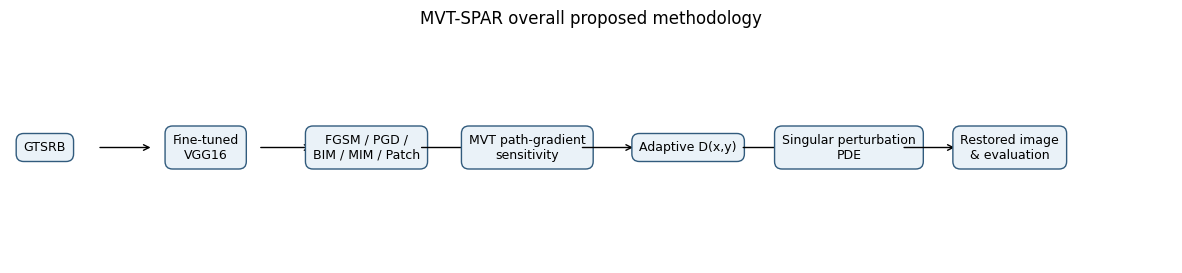

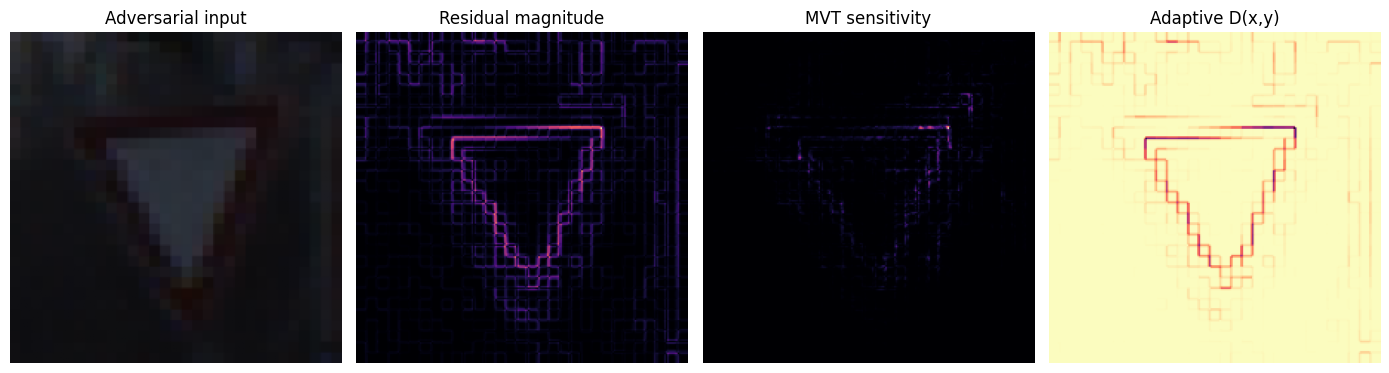

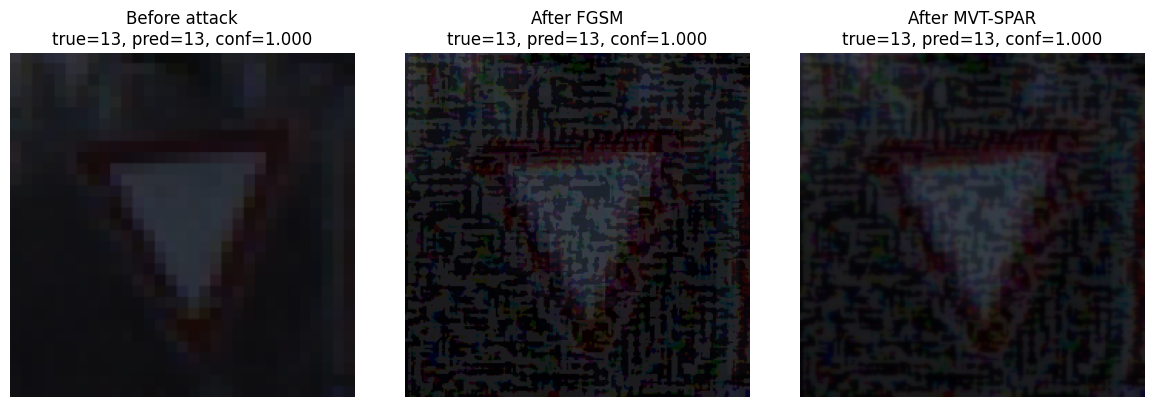

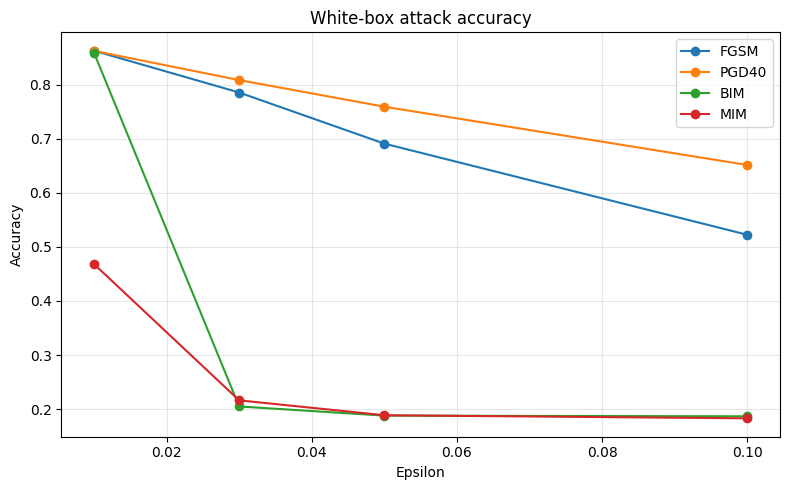

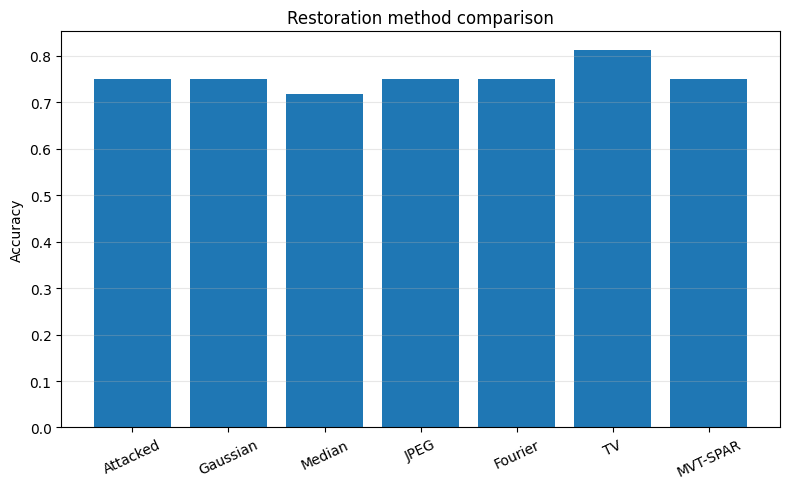

In [24]:
FIG=os.path.join(ROOT_OUT,'Figures')
# Overall methodology diagram
fig,ax=plt.subplots(figsize=(15,3)); ax.axis('off')
steps=['GTSRB','Fine-tuned\nVGG16','FGSM / PGD /\nBIM / MIM / Patch',
       'MVT path-gradient\nsensitivity','Adaptive D(x,y)','Singular perturbation\nPDE','Restored image\n& evaluation']
xs=np.linspace(.03,.86,len(steps))
for i,(x0,label) in enumerate(zip(xs,steps)):
    ax.text(x0,.5,label,transform=ax.transAxes,ha='center',va='center',
            bbox=dict(boxstyle='round,pad=.6',fc='#eaf2f8',ec='#315b7d'),fontsize=9)
    if i<len(steps)-1:
        ax.annotate('',xy=(xs[i+1]-.045,.5),xytext=(x0+.045,.5),xycoords=ax.transAxes,
                    arrowprops=dict(arrowstyle='->'))
ax.set_title('MVT-SPAR overall proposed methodology')
fig.savefig(os.path.join(FIG,'fig1_methodology.png'),dpi=300,bbox_inches='tight')
fig.savefig(os.path.join(FIG,'fig1_methodology.pdf'),bbox_inches='tight')
plt.show()

# Sensitivity visualization from pilot
fig,axs=plt.subplots(1,4,figsize=(14,4))
axs[0].imshow(pilot_x[0]); axs[0].set_title('Adversarial input')
axs[1].imshow(np.mean(np.abs(pilot_res[0]),axis=-1),cmap='magma'); axs[1].set_title('Residual magnitude')
axs[2].imshow(pilot_sens[0,:,:,0],cmap='magma'); axs[2].set_title('MVT sensitivity')
axs[3].imshow(pilot_D[0,:,:,0],cmap='magma'); axs[3].set_title('Adaptive D(x,y)')
for a in axs:a.axis('off')
fig.tight_layout()
fig.savefig(os.path.join(FIG,'fig2_mvt_spatial_coefficients.png'),dpi=300,bbox_inches='tight')
fig.savefig(os.path.join(FIG,'fig2_mvt_spatial_coefficients.pdf'),bbox_inches='tight')
plt.show()

# One clean / attacked / defended example
sample_clean=pilot_x[:1]
sample_label=y_test[:1]
sample_adv=attack_batch(sample_clean,sample_label,'FGSM',0.05)
r,s=mvt_sensitivity_batch(sample_adv,sample_label)
d=diffusion_coefficient(sample_adv,s)
sample_def,_=pde_jacobi_batch(tf.constant(sample_adv),tf.constant(d))
fig,axs=plt.subplots(1,3,figsize=(12,4))
for ax,img,title in zip(axs,[sample_clean[0],sample_adv[0],sample_def.numpy()[0]],
                        ['Before attack','After FGSM','After MVT-SPAR']):
    pr=model(img[None],training=False).numpy()[0]
    ax.imshow(img); ax.set_title(f'{title}\ntrue={sample_label[0]}, pred={pr.argmax()}, conf={pr.max():.3f}'); ax.axis('off')
fig.tight_layout()
fig.savefig(os.path.join(FIG,'fig3_before_after_defense.png'),dpi=300,bbox_inches='tight')
fig.savefig(os.path.join(FIG,'fig3_before_after_defense.pdf'),bbox_inches='tight')
plt.show()

# Quantitative plots
if os.path.exists(os.path.join(ROOT_OUT,'Results_CSV','whitebox_attack_results.csv')):
    wdf=pd.read_csv(os.path.join(ROOT_OUT,'Results_CSV','whitebox_attack_results.csv'))
    fig,ax=plt.subplots(figsize=(8,5))
    for attack in wdf.attack.unique():
        dd=wdf[wdf.attack==attack].sort_values('epsilon')
        ax.plot(dd.epsilon,dd.accuracy,marker='o',label=attack)
    ax.set_xlabel('Epsilon'); ax.set_ylabel('Accuracy'); ax.set_title('White-box attack accuracy')
    ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
    fig.savefig(os.path.join(FIG,'fig4_attack_accuracy.png'),dpi=300,bbox_inches='tight')
    fig.savefig(os.path.join(FIG,'fig4_attack_accuracy.pdf'),bbox_inches='tight')
    plt.show()

if len(comparison_df):
    fig,ax=plt.subplots(figsize=(8,5))
    ax.bar(comparison_df.method,comparison_df.accuracy)
    ax.set_ylabel('Accuracy'); ax.set_title('Restoration method comparison')
    ax.tick_params(axis='x',rotation=25); ax.grid(axis='y',alpha=.3); fig.tight_layout()
    fig.savefig(os.path.join(FIG,'fig5_restoration_comparison.png'),dpi=300,bbox_inches='tight')
    fig.savefig(os.path.join(FIG,'fig5_restoration_comparison.pdf'),bbox_inches='tight')
    plt.show()

## 25. Save model, tables, configuration and confusion matrix

In [25]:
model.save(os.path.join(ROOT_OUT,'Trained_Models','final_vgg16.keras'))
pd.DataFrame(confusion_matrix(y_test,clean_pred)).to_csv(
    os.path.join(ROOT_OUT,'Results_CSV','clean_confusion_matrix.csv'),index=False)
config={'seed':SEED,'test_size':TEST_SIZE,'image_size':IMG_SIZE,'train_batch':TRAIN_BATCH,
        'eval_batch':EVAL_BATCH,'epsilons':EPSILONS,'patch_sizes':PATCH_SIZES,
        'attack_steps':ATTACK_STEPS,'mvt_K':MVT_K,'pde_jacobi_steps':PDE_JACOBI_STEPS,
        'pde_epsilon':PDE_EPSILON,'pde_lambda':PDE_LAMBDA,
        'mvt_alpha':MVT_ALPHA,'edge_beta':EDGE_BETA,'defense_limit':DEFENSE_LIMIT,
        'clean_test_accuracy':float(clean_acc)}
with open(os.path.join(ROOT_OUT,'Logs','experiment_config.json'),'w') as f:
    json.dump(config,f,indent=2)
print("Saved model and experiment metadata.")

Saved model and experiment metadata.


## 26. Generate PDF report

In [26]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate,Paragraph,Spacer,Image as RLImage,Table,TableStyle
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors
from reportlab.lib.units import inch

pdf_path=os.path.join(ROOT_OUT,'PDF_Report','MVT_SPAR_GTSRB_Report.pdf')
styles=getSampleStyleSheet()
story=[Paragraph('MVT-SPAR: GTSRB Adversarial Restoration',styles['Title']),Spacer(1,12),
       Paragraph(f'Train images: {len(train_paths)} | Held-out test images: {len(test_paths)} | '
                 f'Clean test accuracy: {clean_acc:.4f}',styles['BodyText']),Spacer(1,12),
       Paragraph('The notebook uses batch-based image loading and disk-backed attack outputs to reduce runtime memory pressure.',styles['BodyText']),Spacer(1,12)]
csvs=['whitebox_attack_results.csv','patch_attack_results.csv','mvt_spar_defense_results.csv','restoration_comparison.csv']
for fn in csvs:
    p=os.path.join(ROOT_OUT,'Results_CSV',fn)
    if os.path.exists(p):
        df=pd.read_csv(p)
        story.append(Paragraph(fn.replace('_',' '),styles['Heading2']))
        if len(df):
            view=df.head(30).copy()
            for c in view.select_dtypes(include=[np.number]).columns:
                view[c]=view[c].map(lambda v:f'{v:.4f}' if pd.notna(v) else 'N/A')
            data=[list(view.columns)]+view.astype(str).values.tolist()
            tbl=Table(data,repeatRows=1)
            tbl.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.lightgrey),
                                     ('GRID',(0,0),(-1,-1),.3,colors.grey),
                                     ('FONTSIZE',(0,0),(-1,-1),6)]))
            story.extend([tbl,Spacer(1,10)])
for fn in sorted(os.listdir(FIG)):
    if fn.endswith('.png'):
        story.append(Paragraph(fn.replace('_',' '),styles['Heading2']))
        story.append(RLImage(os.path.join(FIG,fn),width=6.5*inch,height=3.4*inch))
        story.append(Spacer(1,8))
SimpleDocTemplate(pdf_path,pagesize=A4).build(story)
print("PDF saved:",pdf_path)

PDF saved: /content/drive/MyDrive/GTSRB-MVT-SPAR/PDF_Report/MVT_SPAR_GTSRB_Report.pdf


## 27. Verify Drive outputs and create ZIP

In [27]:
for root,dirs,files in os.walk(ROOT_OUT):
    print(root, 'files:',len(files))
archive='/content/GTSRB-MVT-SPAR-output.zip'
shutil.make_archive(archive[:-4],'zip',ROOT_OUT)
print("Archive ready:",archive)
print("PDF:",pdf_path)

/content/drive/MyDrive/GTSRB-MVT-SPAR files: 0
/content/drive/MyDrive/GTSRB-MVT-SPAR/Dataset_Split files: 1
/content/drive/MyDrive/GTSRB-MVT-SPAR/Trained_Models files: 3
/content/drive/MyDrive/GTSRB-MVT-SPAR/Adversarial_Images files: 40
/content/drive/MyDrive/GTSRB-MVT-SPAR/Restored_Images files: 40
/content/drive/MyDrive/GTSRB-MVT-SPAR/Results_CSV files: 7
/content/drive/MyDrive/GTSRB-MVT-SPAR/Figures files: 10
/content/drive/MyDrive/GTSRB-MVT-SPAR/PDF_Report files: 1
/content/drive/MyDrive/GTSRB-MVT-SPAR/Logs files: 1
/content/drive/MyDrive/GTSRB-MVT-SPAR/Checkpoints files: 2
Archive ready: /content/GTSRB-MVT-SPAR-output.zip
PDF: /content/drive/MyDrive/GTSRB-MVT-SPAR/PDF_Report/MVT_SPAR_GTSRB_Report.pdf


## 28. Download ZIP and PDF

In [28]:
from google.colab import files
files.download('/content/GTSRB-MVT-SPAR-output.zip')
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

## Runtime and research cautions

- The first run should use `DEFENSE_LIMIT = 64`, `MVT_K = 5`, and `PDE_JACOBI_STEPS = 40`. Increase gradually only after the pilot finishes without runtime restart.
- To process all 4,000 test images after validation, set `DEFENSE_LIMIT = 4000` and rerun the defense cell. The defense output files are saved per condition.
- Training can still take substantial time. Colab session time limits are separate from RAM stability; save checkpoints and rerun after reconnecting.
- MVT-SPAR's sampled path-gradient estimator is MVT-inspired; it does not identify the unknown exact MVT point.
- The Gaussian residual includes edges and texture, not only adversarial noise.
- The fixed black square is a patch occlusion test, not an optimized adversarial patch.
- The finite-iteration Jacobi PDE solver is an approximate numerical solve. Report its relative residual and increase iterations or use a stronger solver if convergence is inadequate.
- Evaluate an adaptive attack that differentiates through the defense before making robustness claims.